# M2Doc — Multi-Modal Document Layout Analysis Pipeline

Pipeline phân tích layout tài liệu đa phương thức bằng **M2Doc** (công bố tại **AAAI 2024** bởi SCUT HCIILAB & Alibaba Group), model mặc định: `Cascade Mask R-CNN (ResNet-50 Backbone)`.

Notebook thực hiện quy trình hoàn chỉnh:
1. **Chạy inference**: Phát hiện các khối layout tài liệu dựa trên sự kết hợp giữa đặc trưng thị giác (visual features) và đặc trưng văn bản ngữ nghĩa (textual features từ Multilingual BERT), xuất kết quả JSON chuẩn COCO.
2. **Đánh giá metric**: Đánh giá theo chuẩn Strict (khớp vị trí IoU >= 0.5 và đúng nhãn) và Loose (chỉ vị trí), tính toán mAP@[0.5:0.95] và mAP@0.5 theo chuẩn COCO, vẽ biểu đồ phân tích.
3. **Trực quan hóa**: Đối chiếu ảnh Ground Truth và dự đoán của M2Doc cạnh nhau để đánh giá trực quan chất lượng nhận diện.

### Kiến trúc Đa phương thức (Multi-Modal Fusion)
- **Early-Fusion (Pixel-level)**: Sử dụng Multilingual BERT (`bert-base-multilingual-cased`) mã hóa các từ và bounding box tương ứng thành biểu diễn lưới (`chargrid_map`), sau đó hòa trộn trực tiếp vào các tầng đặc trưng sớm của ResNet-50.
- **Late-Fusion (Block-level)**: Tại tầng RoI Head (Cascade Mask R-CNN), tính ma trận tương quan IoU giữa các bounding box đề xuất và khối văn bản để chiếu đặc trưng ngữ nghĩa vào từng vùng đối tượng trước khi phân loại và hồi quy.
- **Taxonomy Mapping**: Do model M2Doc được huấn luyện trực tiếp trên tập dữ liệu chuẩn DocLayNet, 11 nhãn đầu ra khớp hoàn toàn 1-1 với 11 danh mục của DocLayNet (Caption, Footnote, Formula, List-item, Page-footer, Page-header, Picture, Section-header, Table, Text, Title).

In [1]:
from pathlib import Path
import subprocess
import sys

# Khởi tạo đường dẫn gốc project
ROOT = Path.cwd().resolve()
while ROOT != ROOT.parent and not (ROOT / "methods").is_dir():
    ROOT = ROOT.parent
if not (ROOT / "methods").is_dir():
    raise FileNotFoundError("Không tìm thấy thư mục gốc repository; hãy mở notebook từ project DO-AN-261.")

METHOD = "m2doc"
DATASET = "doclaynet_test"
SPLIT = "test"
IOU_THRESHOLD = 0.5
LIMIT = 0  # 0: toan bo anh trong tap du lieu
FORCE_INFERENCE = False  # True: chạy lại inference và ghi đè; False: bỏ qua ảnh đã có prediction
FIGURE_LIMIT = 0  # 0: toan bo anh trong tap du lieu

PREDICTIONS_DIR = ROOT / "outputs" / "predictions" / METHOD / DATASET
FIGURES_DIR = ROOT / "outputs" / "reports" / f"{METHOD}_{DATASET}"
print(f"Project: {ROOT}")
print(f"Pipeline: {METHOD} | {DATASET}/{SPLIT} | IoU >= {IOU_THRESHOLD}")
print(f"Inference: {'force rerun' if FORCE_INFERENCE else 'skip existing predictions'}")
print(f"Predictions: {PREDICTIONS_DIR}")
print(f"Figures: {FIGURES_DIR}")

Project: D:\DLA\DO-AN-261
Pipeline: m2doc | doclaynet_test/test | IoU >= 0.5
Inference: skip existing predictions
Predictions: D:\DLA\DO-AN-261\outputs\predictions\m2doc\doclaynet_test
Figures: D:\DLA\DO-AN-261\outputs\reports\m2doc_doclaynet_test


## 0. Kiểm tra mã nguồn, môi trường và tự động tải trọng số (Setup & Auto-Download)

Tế bào này kiểm tra sự tồn tại của thư mục mã nguồn M2Doc MMDetection, bộ trọng số chính thức (Cascade Mask R-CNN ResNet-50) và tập dữ liệu. Nếu chưa có file trọng số pre-trained, hệ thống sẽ tự động tải về từ Google Drive thông qua `gdown` để người dùng có thể chạy trực tiếp toàn bộ notebook mà không cần thao tác thủ công.

In [2]:
import subprocess
import sys
from pathlib import Path

# 1. Kiểm tra và tự động clone mã nguồn MMDetection tùy biến của M2Doc
mmdet_dir = ROOT / "methods" / "m2doc" / "mmdetection"
if not mmdet_dir.is_dir() or not (mmdet_dir / "mmdet").is_dir():
    print("[Setup] Chưa tìm thấy mã nguồn MMDetection của M2Doc. Đang tự động clone từ GitHub...")
    import tempfile
    import shutil
    with tempfile.TemporaryDirectory() as tmpdir:
        clone_cmd = ["git", "clone", "--depth", "1", "https://github.com/johnning2333/M2Doc.git", tmpdir]
        subprocess.check_call(clone_cmd)
        src_mmdet = Path(tmpdir) / "mmdetection"
        if src_mmdet.is_dir():
            shutil.copytree(src_mmdet, mmdet_dir, dirs_exist_ok=True)
            print("[OK] Clone và thiết lập mã nguồn MMDetection thành công!")
        else:
            raise RuntimeError("Không tìm thấy thư mục mmdetection trong repository M2Doc vừa clone.")
else:
    print(f"[OK] Thư mục mã nguồn M2Doc MMDetection: {mmdet_dir.name}")

# 2. Kiểm tra thư viện gdown
try:
    import gdown
except ImportError:
    print("[Setup] Đang cài đặt thư viện gdown...")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "gdown"])
    import gdown

# 3. Kiểm tra và tự động tải trọng số pre-trained nếu chưa có
weights_dir = ROOT / "methods" / "m2doc" / "weights"
weights_dir.mkdir(parents=True, exist_ok=True)
weights_file = weights_dir / "cascade_mask_rcnn_m2doc_r50.pth"
GDRIVE_WEIGHTS_ID = "14cf3cmVMWTG8g6w0qMd_lkKYfyR0EDX-"

if not weights_file.exists() or weights_file.stat().st_size < 1000000:
    print("[Setup] Chưa có file trọng số M2Doc. Đang tự động tải về từ Google Drive...")
    print(f"[Setup] Target: {weights_file}")
    gdown.download(id=GDRIVE_WEIGHTS_ID, output=str(weights_file), quiet=False)
    if weights_file.exists() and weights_file.stat().st_size > 1000000:
        print(f"[OK] Tải trọng số thành công ({weights_file.stat().st_size / (1024*1024):.2f} MB)!")
    else:
        raise FileNotFoundError("Không thể tải trọng số tự động. Vui lòng tải thủ công theo README.md.")
else:
    print(f"[OK] File trọng số đã sẵn sàng: {weights_file.name} ({weights_file.stat().st_size / (1024*1024):.2f} MB)")

# 4. Kiểm tra tập dữ liệu DocLayNet
images_dir = ROOT / "datasets" / DATASET / "processed" / "images"
if not images_dir.is_dir() or not any(images_dir.glob("*.png")):
    print(f"[Cảnh báo] Chưa tìm thấy ảnh tại: {images_dir}. Hãy đảm bảo đã chuẩn bị dataset trước khi chạy inference.")
else:
    num_images = len(list(images_dir.glob("*.png")))
    print(f"[OK] Tập dữ liệu {DATASET} sẵn sàng ({num_images} ảnh).")


[OK] Thư mục mã nguồn M2Doc MMDetection: mmdetection


[Setup] Chưa có file trọng số M2Doc. Đang tự động tải về từ Google Drive...
[Setup] Target: D:\DLA\DO-AN-261\methods\m2doc\weights\cascade_mask_rcnn_m2doc_r50.pth


Downloading...
From (original): https://drive.google.com/uc?id=14cf3cmVMWTG8g6w0qMd_lkKYfyR0EDX-
From (redirected): https://drive.google.com/uc?id=14cf3cmVMWTG8g6w0qMd_lkKYfyR0EDX-&confirm=t&uuid=93b0e504-5bdf-4279-ba52-928c3c40f814
To: D:\DLA\DO-AN-261\methods\m2doc\weights\cascade_mask_rcnn_m2doc_r50.pth


  0%|          | 0.00/1.48G [00:00<?, ?B/s]

  0%|          | 524k/1.48G [00:00<12:21, 2.00MB/s]

...

100%|█████████▉| 1.48G/1.48G [03:55<00:00, 7.53MB/s]

100%|█████████▉| 1.48G/1.48G [03:56<00:00, 8.10MB/s]

100%|█████████▉| 1.48G/1.48G [03:56<00:00, 7.66MB/s]

100%|██████████| 1.48G/1.48G [03:56<00:00, 6.27MB/s]

[OK] Tải trọng số thành công (1413.22 MB)!
[OK] Tập dữ liệu doclaynet_test sẵn sàng (4999 ảnh).


## 1. Prediction

Chạy layout detection bằng script `methods/m2doc/src/run_inference.py`. Script nạp model Cascade Mask R-CNN kết hợp mạng trích xuất text grid BERT và sinh kết quả dự đoán ra `outputs/predictions/m2doc/<dataset>/`.

In [3]:
inference_script = ROOT / "methods" / METHOD / "src" / "run_inference.py"
command = [
    sys.executable,
    str(inference_script),
    "--dataset", DATASET,
    "--limit", str(LIMIT),
    "--force" if FORCE_INFERENCE else "--skip-existing",
]
print("Running:", " ".join(command))
res = subprocess.run(command, cwd=ROOT, capture_output=True, text=True, check=True)
print(res.stdout)
print(f"Predictions: {PREDICTIONS_DIR}")

Running: D:\DLA\docling_env\Scripts\python.exe D:\DLA\DO-AN-261\methods\m2doc\src\run_inference.py --dataset doclaynet_test --limit 0 --skip-existing


Exception in thread Thread-4 (_readerthread):
Traceback (most recent call last):
  File "C:\Users\Admin\anaconda3\Lib\threading.py", line 1041, in _bootstrap_inner
    self.run()
    ~~~~~~~~^^
  File "C:\Users\Admin\anaconda3\Lib\threading.py", line 992, in run
    self._target(*self._args, **self._kwargs)
    ~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\Admin\anaconda3\Lib\subprocess.py", line 1611, in _readerthread
    buffer.append(fh.read())
                  ~~~~~~~^^
  File "C:\Users\Admin\anaconda3\Lib\encodings\cp1252.py", line 23, in decode
    return codecs.charmap_decode(input,self.errors,decoding_table)[0]
           ~~~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
UnicodeDecodeError: 'charmap' codec can't decode byte 0x8f in position 2407: character maps to <undefined>


[m2doc] 4999 image(s) to predict from D:\DLA\DO-AN-261\datasets\doclaynet_test\processed\images (threshold: 0.3, device: cuda, use_ocr: True) (existing predictions skipped)
[m2doc] Loading M2Doc model from: D:\DLA\DO-AN-261\methods\m2doc\weights\cascade_mask_rcnn_m2doc_r50.pth
encoder.layer.11.attention.self.query.weight
encoder.layer.11.attention.self.query.bias
encoder.layer.11.attention.self.key.weight
encoder.layer.11.attention.self.key.bias
encoder.layer.11.attention.self.value.weight
encoder.layer.11.attention.self.value.bias
encoder.layer.11.attention.output.dense.weight
encoder.layer.11.attention.output.dense.bias
encoder.layer.11.attention.output.LayerNorm.weight
encoder.layer.11.attention.output.LayerNorm.bias
encoder.layer.11.intermediate.dense.weight
encoder.layer.11.intermediate.dense.bias
encoder.layer.11.output.dense.weight
encoder.layer.11.output.dense.bias
encoder.layer.11.output.LayerNorm.weight
encoder.layer.11.output.LayerNorm.bias
[m2doc] M2Doc model ready for infe

## 2. Metrics and Evaluation Chart

Đánh giá kết quả trên tập ảnh vừa thực thi inference (`outputs/predictions/m2doc/doclaynet/`).
- **Strict**: Yêu cầu khớp cả tọa độ (IoU >= threshold) và đúng nhãn layout.
- **Loose**: Chỉ đánh giá khả năng định vị (localization), bỏ qua nhãn.
- **COCO mAP**: mAP@[.5:.95] và mAP@.5 theo tiêu chuẩn COCO benchmark.
- **Biểu đồ**: Trực quan hóa Precision, Recall, F1 theo từng class và so sánh Strict vs Loose.

Running evaluation:


Evaluation: m2doc on doclaynet_test/test | 4999 images | GT=66,531 boxes | Predictions=8,599 boxes | IoU >= 0.5

=== Strict (location and class) ===
Micro: Precision=0.019  Recall=0.002  F1=0.004  TP=164 FP=8435 FN=66367  mean IoU=0.796
Macro (mean across 11 ground-truth classes): Precision=0.002  Recall=0.004  F1=0.002
Class                   GT    Pred     TP     FP     FN     Prec   Recall       F1
Text                 29940       0      0      0  29940    0.000    0.000    0.000
List-item            10522      99      0     99  10522    0.000    0.000    0.000
Section-header        8550       0      0      0   8550    0.000    0.000    0.000
Page-footer           3994    8398    164   8234   3830    0.020    0.041    0.026
Picture               3534       0      0      0   3534    0.000    0.000    0.000
Page-header           3366       0      0      0   3366    0.000    0.000    0.000
Table                 2394       0      0      0   2394    0.000    0.000    0.000
Formula       

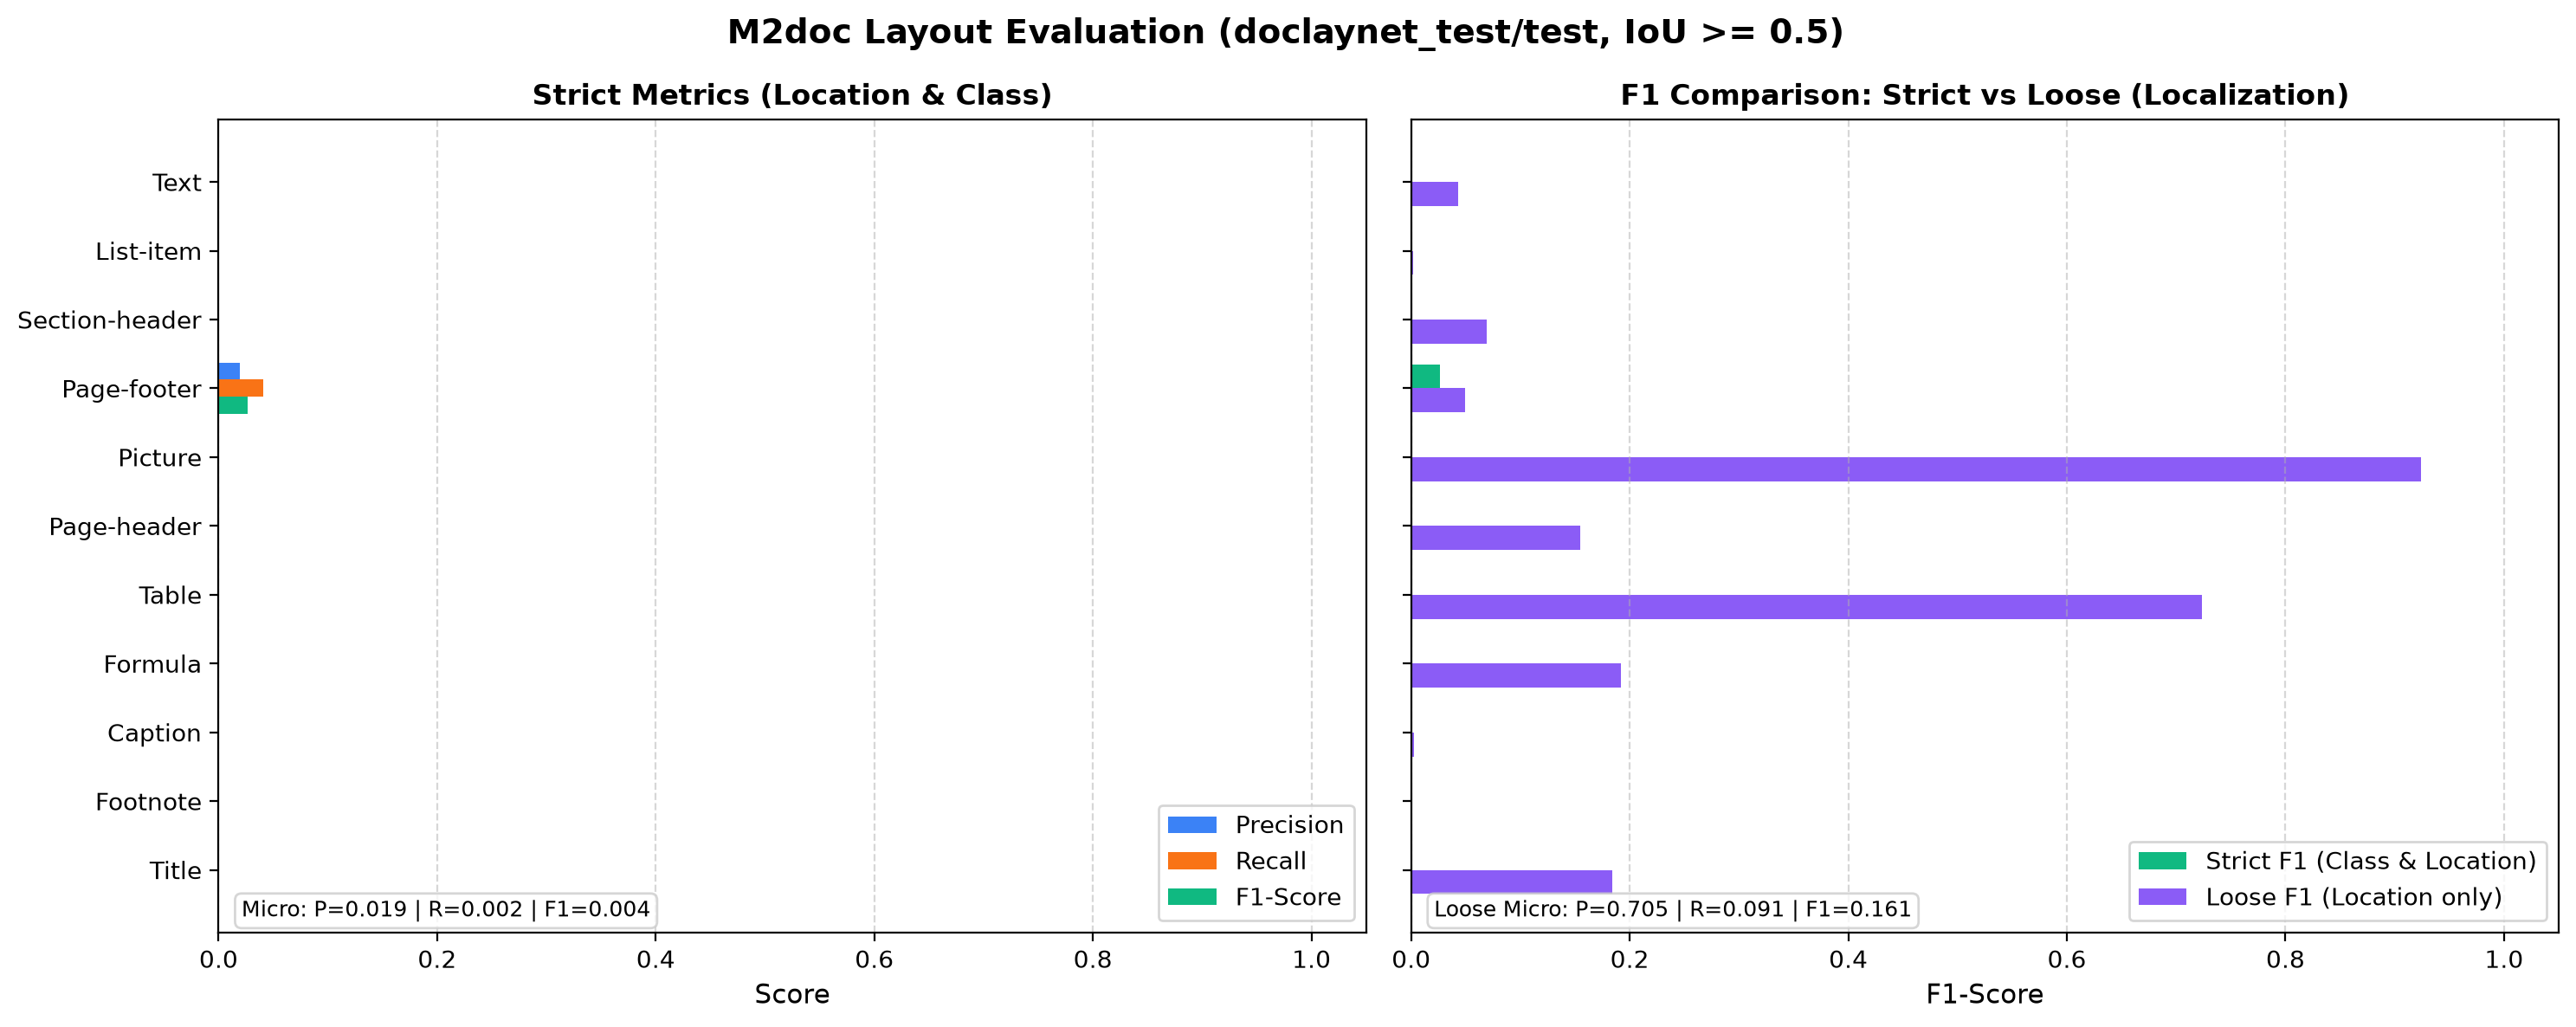

In [4]:
eval_script = ROOT / "scripts" / "evaluate_predictions.py"
eval_command = [
    sys.executable,
    str(eval_script),
    "--method", METHOD,
    "--dataset", DATASET,
    "--split", SPLIT,
    "--iou-threshold", str(IOU_THRESHOLD),
    "--loose",
    "--allow-incomplete",
    "--plot",
]
print("Running evaluation:")
res = subprocess.run(eval_command, cwd=ROOT, capture_output=True, text=True, check=True)
print(res.stdout)

# Hiển thị biểu đồ đánh giá
chart_file = FIGURES_DIR / "metrics_chart.png"
if chart_file.is_file():
    from IPython.display import Image as DisplayImage, display
    print(f"Evaluation Chart ({chart_file}):")
    display(DisplayImage(filename=str(chart_file)))

## 3. Ground Truth vs. Prediction Examples

Trực quan hóa đối chiếu ảnh Ground Truth và kết quả dự đoán của M2Doc. Ảnh kết quả được lưu tại `outputs/reports/m2doc_doclaynet/`.

Running: D:\DLA\docling_env\Scripts\python.exe D:\DLA\DO-AN-261\visualization\scripts\visualize_predictions.py --method m2doc --dataset doclaynet_test --split test --limit 0 --output-dir D:\DLA\DO-AN-261\outputs\reports\m2doc_doclaynet_test


[viz] Ve 4999 anh (m2doc vs ground truth) tu D:\DLA\DO-AN-261\visualization\scripts\..\..\outputs\predictions\m2doc\doclaynet_test
  [ok] 1.png
  [ok] 2.png
  [ok] 3.png
  [ok] 4.png
  [ok] 5.png
  [ok] 6.png
  [ok] 7.png
  [ok] 8.png
  [ok] 9.png
  [ok] 10.png
  [ok] 11.png
  [ok] 13.png
  [ok] 14.png
  [ok] 15.png
  [ok] 16.png
  [ok] 17.png
  [ok] 18.png
  [ok] 19.png
  [ok] 20.png
  [ok] 21.png
  [ok] 22.png
  [ok] 23.png
  [ok] 24.png
  [ok] 25.png
  [ok] 26.png
  [ok] 27.png
  [ok] 28.png
  [ok] 29.png
  [ok] 30.png
  [ok] 31.png
  [ok] 32.png
  [ok] 34.png
  [ok] 35.png
  [ok] 36.png
  [ok] 39.png
  [ok] 41.png
  [ok] 42.png
  [ok] 43.png
  [ok] 44.png
  [ok] 45.png
  [ok] 46.png
  [ok] 47.png
  [ok] 48.png
  [ok] 49.png
  [ok] 50.png
  [ok] 51.png
  [ok] 52.png
  [ok] 54.png
  [ok] 55.png
  [ok] 56.png
  [ok] 57.png
  [ok] 59.png
  [ok] 60.png
  [ok] 62.png
  [ok] 63.png
  [ok] 64.png
  [ok] 65.png
  [ok] 66.png
  [ok] 67.png
  [ok] 68.png
  [ok] 69.png
  [ok] 70.png
  [ok] 71.

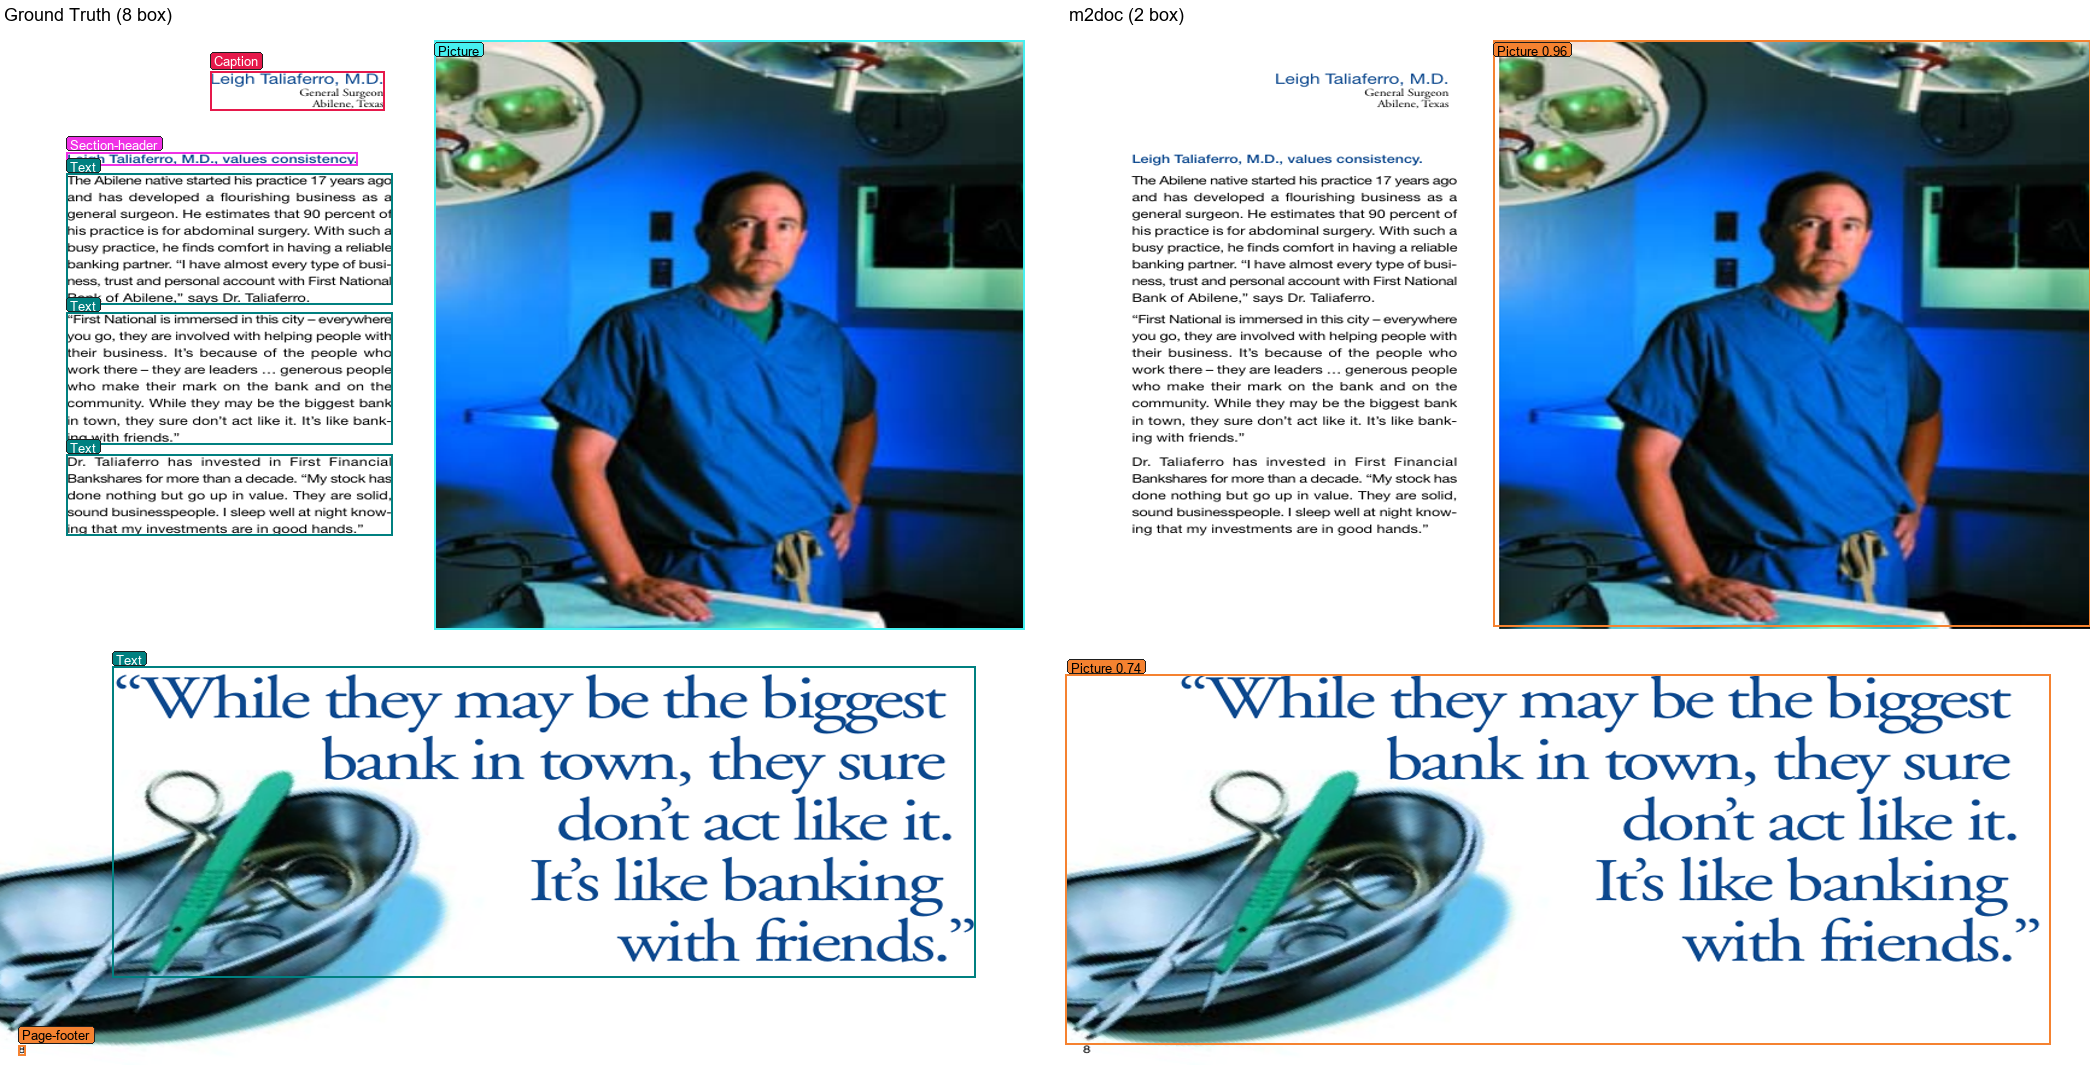

Ví dụ ảnh đối chiếu: D:\DLA\DO-AN-261\outputs\reports\m2doc_doclaynet_test\10.png


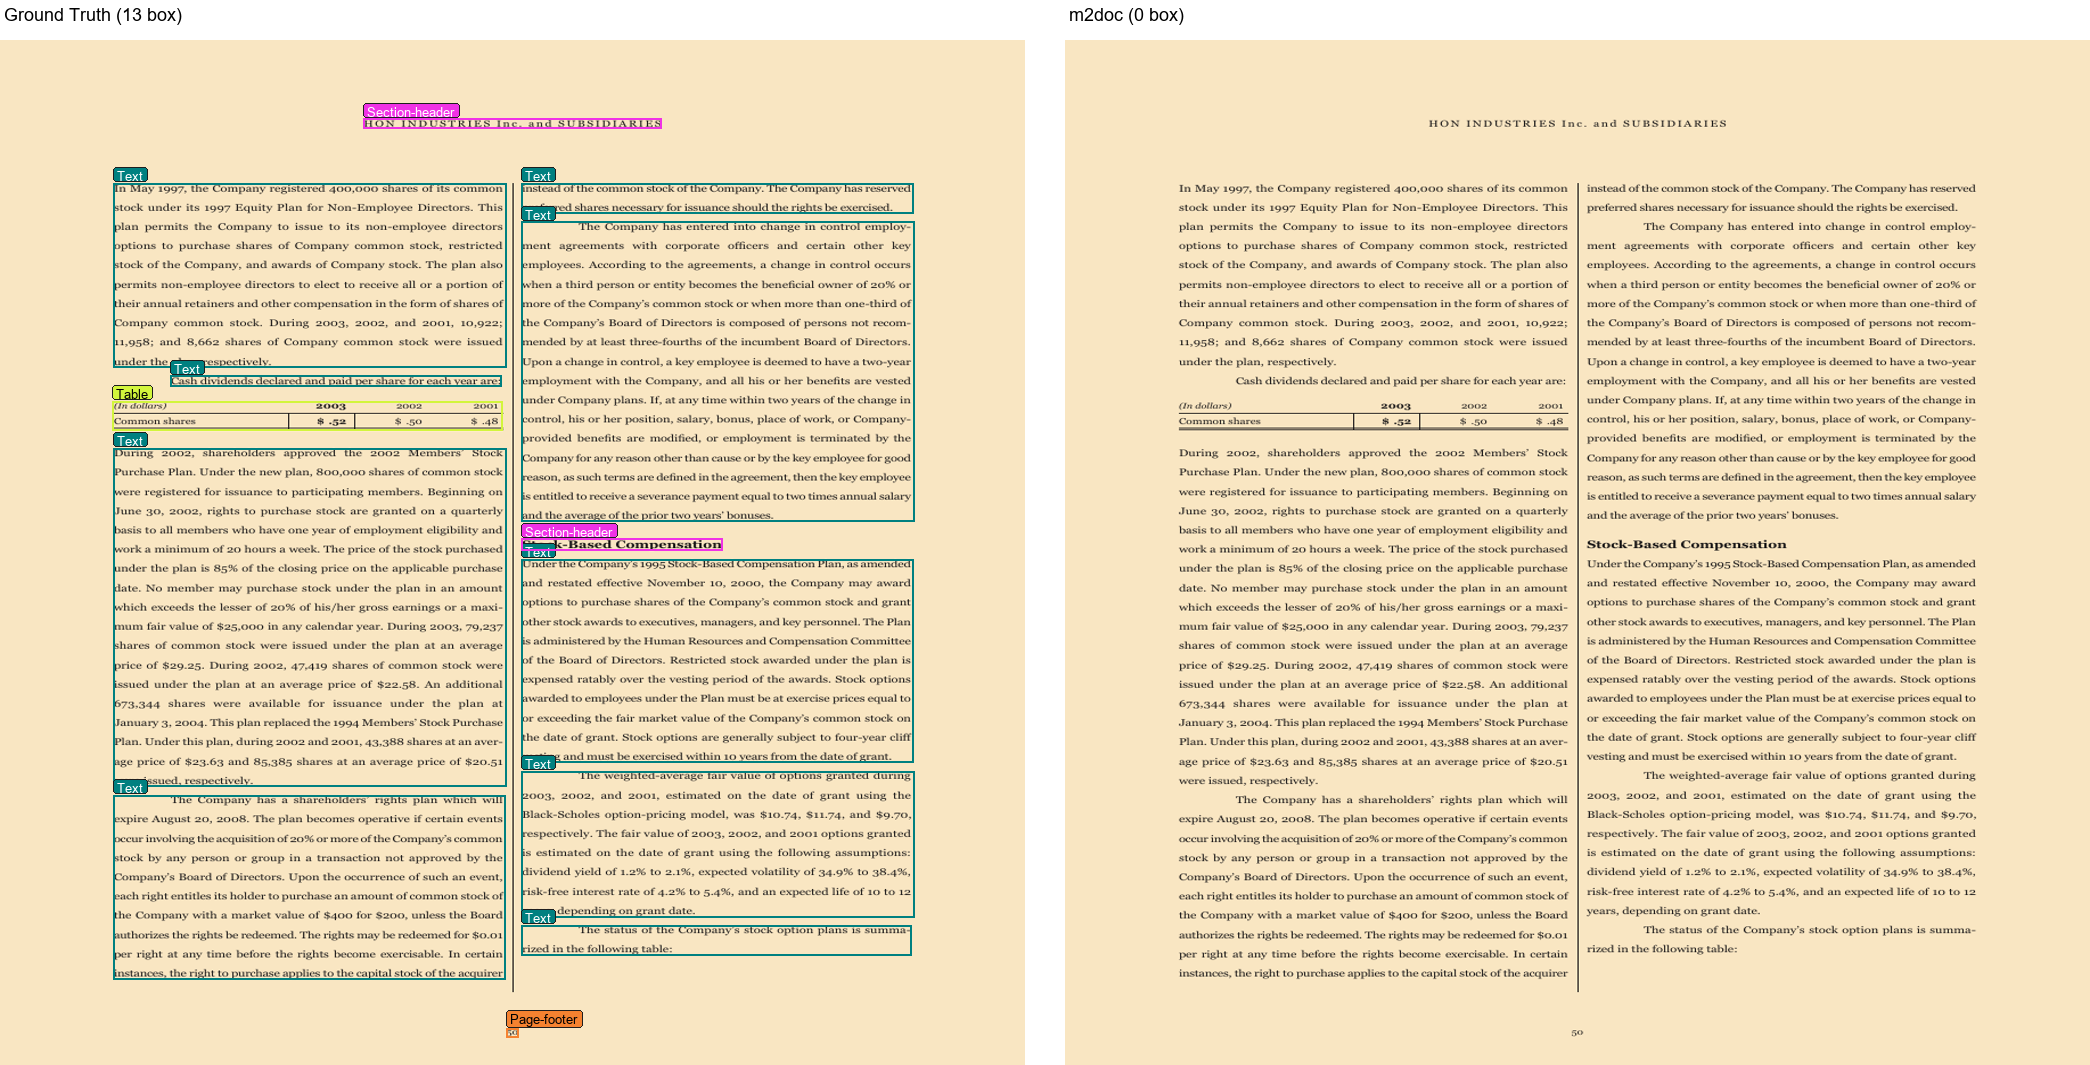

In [5]:
viz_script = ROOT / "visualization" / "scripts" / "visualize_predictions.py"
viz_command = [
    sys.executable,
    str(viz_script),
    "--method", METHOD,
    "--dataset", DATASET,
    "--split", SPLIT,
    "--limit", str(FIGURE_LIMIT),
    "--output-dir", str(FIGURES_DIR),
]
print("Running:", " ".join(viz_command))
res = subprocess.run(viz_command, cwd=ROOT, capture_output=True, text=True, check=True)
print(res.stdout)

# Hiển thị một số ảnh minh họa đối chiếu Ground Truth vs Prediction
from IPython.display import Image as DisplayImage, display
sample_images = sorted(FIGURES_DIR.glob("*.png"))
sample_images = [img for img in sample_images if img.name != "metrics_chart.png"]
if sample_images:
    for img_path in sample_images[:2]:
        print(f"Ví dụ ảnh đối chiếu: {img_path}")
        display(DisplayImage(filename=str(img_path)))